<a href="https://colab.research.google.com/github/atticusptp-cloud/CAPSTONE/blob/main/capstone_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd                      # data manipulation and preparation
import numpy as np                       # numeric calculations
import matplotlib.pyplot as plt          # charts
import seaborn as sns                    # advanced charts
from scipy import stats                  # z-scores for outlier detection

# To filter out unnecessary warnings in the output
import warnings
warnings.filterwarnings("ignore")

In [ ]:

# File names stored in a dictionary: table name -> file path
files = {
    "Bookings": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Bookings.csv",
    "Hotels": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Hotels.csv",
    "Market_Segments": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Market%20Segments.csv",
    "Customer_Types": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Customer%20Types.csv",
    "Reservation_Status": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Reservation%20Status.csv",
}

tables = {}
for name, path in files.items():
    try:
        tables[name] = pd.read_csv(path)
        print(f"{name}: {tables[name].shape[0]} rows, {tables[name].shape[1]} columns")
    except FileNotFoundError:
        print(f"Error: {path} was not found. Check that the data folder is next to this notebook.")

bookings = tables["Bookings"]
hotels = tables["Hotels"]
segments = tables["Market_Segments"]
customers = tables["Customer_Types"]
status = tables["Reservation_Status"]

Bookings: 119390 rows, 28 columns
Hotels: 2 rows, 2 columns
Market_Segments: 26 rows, 3 columns
Customer_Types: 36 rows, 4 columns
Reservation_Status: 3 rows, 2 columns


In [ ]:
display(bookings.head())
display(hotels)
display(segments.head())
display(customers.head())
display(status)

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,3,NaN,NaN,0,0.0,0,0,2015-07-01
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,4,NaN,NaN,0,0.0,0,0,2015-07-01
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,0,NaN,NaN,0,75.0,0,0,2015-07-02
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,0,304.0,NaN,0,75.0,0,0,2015-07-02
4,5,1,3,1,1,0,14,2015,July,27,...,0,0,0,240.0,NaN,0,98.0,0,1,2015-07-03


,Hotel_ID,hotel
0,1,Resort Hotel
1,2,City Hotel


,Market_Segment_ID,market_segment,distribution_channel
0,1,Direct,Direct
1,2,Corporate,Corporate
2,3,Online TA,TA/TO
3,4,Offline TA/TO,TA/TO
4,5,Complementary,Direct


,Customer_Type_ID,customer_type,deposit_type,meal
0,1,Transient,No Deposit,BB
1,2,Transient,No Deposit,FB
2,3,Transient,No Deposit,HB
3,4,Contract,No Deposit,BB
4,5,Contract,No Deposit,HB


,Reservation_ID,reservation_status
0,1,Check-Out
1,2,Canceled
2,3,No-Show


In [ ]:
# Joining the lookup tables to the bookings table (left join keeps every booking)
df = pd.merge(bookings, hotels, on="Hotel_ID", how="left")
df = pd.merge(df, segments, on="Market_Segment_ID", how="left")
df = pd.merge(df, customers, on="Customer_Type_ID", how="left")
df = pd.merge(df, status, on="Reservation_ID", how="left")

print("Rows before join:", len(bookings))
print("Rows after join: ", len(df))
print("Columns after join:", df.shape[1])
df.head()

Rows before join: 119390
Rows after join:  119390
Columns after join: 35


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,required_car_parking_spaces,total_of_special_requests,reservation_status_date,hotel,market_segment,distribution_channel,customer_type,deposit_type,meal,reservation_status
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,2015-07-02,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,2015-07-02,Resort Hotel,Corporate,Corporate,Transient,No Deposit,BB,Check-Out
4,5,1,3,1,1,0,14,2015,July,27,...,0,1,2015-07-03,Resort Hotel,Online TA,TA/TO,Transient,No Deposit,BB,Check-Out


In [ ]:
# Overall information: columns, data types, non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 35 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Booking_ID                      119390 non-null  int64  
 1   Hotel_ID                        119390 non-null  int64  
 2   Market_Segment_ID               119390 non-null  int64  
 3   Customer_Type_ID                119390 non-null  int64  
 4   Reservation_ID                  119390 non-null  int64  
 5   is_canceled                     119390 non-null  int64  
 6   lead_time                       119390 non-null  int64  
 7   arrival_date_year               119390 non-null  int64  
 8   arrival_date_month              119390 non-null  object 
 9   arrival_date_week_number        119390 non-null  int64  
 10  arrival_date_day_of_month       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [ ]:
# Metadata about the dataset (structural metadata)
metadata = {
    "row_count": len(df),
    "column_count": len(df.columns),
    "missing_values": df.isnull().sum()[df.isnull().sum() > 0].to_dict(),
}
print(metadata)

{'row_count': 119390, 'column_count': 35, 'missing_values': {'children': 4, 'country': 488, 'agent': 16340, 'company': 112593}}


In [ ]:
# Statistical description of the numerical columns
df.describe()

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,...,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,0.370416,104.011416,2016.156554,27.165173,15.798241,...,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,34465.068657,0.472181,3.071532,5.250009,0.505913,0.482918,106.863097,0.707476,13.605138,8.780829,...,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,0.000000,18.000000,2016.000000,16.000000,8.000000,...,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,0.000000,69.000000,2016.000000,28.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,1.000000,160.000000,2017.000000,38.000000,23.000000,...,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,119390.000000,2.000000,26.000000,36.000000,3.000000,1.000000,737.000000,2017.000000,53.000000,31.000000,...,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
# Missing values in each column
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

children         4
country        488
agent        16340
company     112593
dtype: int64


In [ ]:
# Data quality checks
print("Duplicate rows (ignoring Booking_ID):", df.drop(columns=["Booking_ID"]).duplicated().sum())
print("Bookings with 0 guests:", len(df[(df["adults"] + df["children"].fillna(0) + df["babies"]) == 0]))
print("Bookings with 0 nights:", len(df[(df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0]))
print("Negative ADR:", len(df[df["adr"] < 0]))
print("Highest ADR:", df["adr"].max())
print("Undefined market segment:", len(df[df["market_segment"] == "Undefined"]))

Duplicate rows (ignoring Booking_ID): 33010
Bookings with 0 guests: 180
Bookings with 0 nights: 715
Negative ADR: 1
Highest ADR: 5400.0
Undefined market segment: 2


In [ ]:
# Consistency check: is_canceled should agree with reservation_status
df.groupby("reservation_status").agg({"is_canceled": ["mean", "count"]})

is_canceled       
                          mean  count
reservation_status                   
Canceled                   1.0  43017
Check-Out                  0.0  75166
No-Show                    1.0   1207

ADR values with |z-score| > 3: 1138
Smallest and largest of these: 253.49 and 5400.0


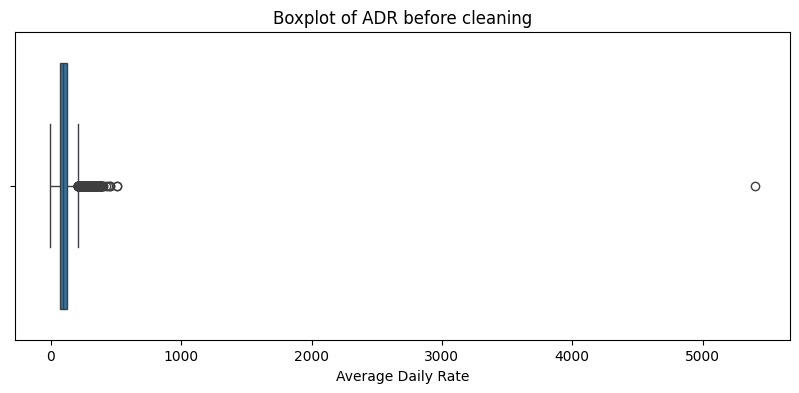

In [16]:
z_scores = stats.zscore(df["adr"])
threshold = 3
outliers = df[abs(z_scores) > threshold]
print("ADR values with |z-score| > 3:", len(outliers))
print("Smallest and largest of these:", outliers["adr"].min(), "and", outliers["adr"].max())

plt.figure(figsize=(10, 4))
sns.boxplot(x="adr", data=df)
plt.title("Boxplot of ADR before cleaning")
plt.xlabel("Average Daily Rate")
plt.show()

In [17]:
rows_before = len(df)

# 1. Fill missing values (fillna returns a new DataFrame, so df keeps the raw data)
clean = df.fillna({"children": 0, "country": "Unknown", "agent": 0, "company": 0})

# 2. Flags for bookings made through an agent / company (missing in the raw data = no agent / company)
clean["has_agent"] = df["agent"].isnull().map({True: 0, False: 1})
clean["has_company"] = df["company"].isnull().map({True: 0, False: 1})
clean["children"] = clean["children"].astype(int)

# 3. New columns
clean["total_guests"] = clean["adults"] + clean["children"] + clean["babies"]
clean["total_nights"] = clean["stays_in_weekend_nights"] + clean["stays_in_week_nights"]

# 4. Remove invalid rows
clean = clean[clean["total_guests"] > 0]
clean = clean[clean["total_nights"] > 0]
clean = clean[clean["adr"] >= 0]
clean = clean[clean["adr"] < 5000]
clean = clean[clean["market_segment"] != "Undefined"]

print("Rows before cleaning:", rows_before)
print("Rows after cleaning: ", len(clean))
print("Rows removed:", rows_before - len(clean), f"({(rows_before - len(clean)) / rows_before * 100:.2f}%)")
print("Missing values left:", clean[["children", "country", "agent", "company"]].isnull().sum().sum())

Rows before cleaning: 119390
Rows after cleaning:  118561
Rows removed: 829 (0.69%)
Missing values left: 0


In [18]:
# Month name -> month number, and month number -> season
month_to_num = {"January": 1, "February": 2, "March": 3, "April": 4, "May": 5, "June": 6, "July": 7,
                "August": 8, "September": 9, "October": 10, "November": 11, "December": 12}
num_to_season = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                 6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}

clean["arrival_month_num"] = clean["arrival_date_month"].map(month_to_num)
clean["season"] = clean["arrival_month_num"].map(num_to_season)
clean["guest_status"] = clean["is_repeated_guest"].map({0: "First-time guest", 1: "Repeat guest"})


# Party type using a function with if / elif / else
def party_type(row):
    if row["children"] + row["babies"] > 0:
        return "Family (with kids)"
    elif row["adults"] == 1:
        return "Solo adult"
    elif row["adults"] == 2:
        return "Couple / 2 adults"
    else:
        return "Group of 3+ adults"


clean["party_type"] = clean.apply(party_type, axis=1)

# Revenue columns: value of the stay, and how much of it was realised or lost
clean["booking_value"] = clean["adr"] * clean["total_nights"]
clean["realised_revenue"] = clean["booking_value"] * (1 - clean["is_canceled"])
clean["lost_revenue"] = clean["booking_value"] * clean["is_canceled"]

# Grouping numeric columns into bands with pd.cut
clean["lead_time_band"] = pd.cut(clean["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 1000],
                                 labels=["0-7 days", "8-30 days", "31-90 days", "91-180 days", "181-365 days", "365+ days"])
clean["stay_band"] = pd.cut(clean["total_nights"], bins=[0, 1, 3, 7, 14, 100],
                            labels=["1 night", "2-3 nights", "4-7 nights", "8-14 nights", "15+ nights"])

clean[["hotel", "arrival_date_month", "season", "total_nights", "party_type", "booking_value", "lost_revenue"]].head()

,hotel,arrival_date_month,season,total_nights,party_type,booking_value,lost_revenue
2,Resort Hotel,July,Summer,1,Solo adult,75.0,0.0
3,Resort Hotel,July,Summer,1,Solo adult,75.0,0.0
4,Resort Hotel,July,Summer,2,Couple / 2 adults,196.0,0.0
5,Resort Hotel,July,Summer,2,Couple / 2 adults,196.0,0.0
6,Resort Hotel,July,Summer,2,Couple / 2 adults,214.0,0.0


In [20]:
# Export the cleaned dataset
clean.to_csv("https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Bookings.csv", index=False)
print("Saved cleaned data:", clean.shape)

Saved cleaned data: (118561, 48)


In [23]:
def kpis(data):
    """Returns the main KPIs of a set of bookings as a dictionary."""
    realised = data["realised_revenue"].sum()
    lost = data["lost_revenue"].sum()
    return {
        "bookings": len(data),
        "cancel_rate_%": float(round(data["is_canceled"].mean() * 100, 1)),
        "avg_adr": float(round(data["adr"].mean(), 2)),
        "realised_revenue": int(round(realised)),
        "lost_revenue": int(round(lost)),
        "lost_share_%": float(round(lost / (realised + lost) * 100, 1)),
    }


def summary_by(column, data=clean):
    """Bookings, cancellation rate, ADR and revenue for each value of a column."""
    table = data.groupby(column).agg({"Booking_ID": "count", "is_canceled": "mean", "adr": "mean",
                                      "realised_revenue": "sum", "lost_revenue": "sum"}).reset_index()
    table = table.rename(columns={"Booking_ID": "bookings", "is_canceled": "cancel_rate", "adr": "avg_adr"})
    table["cancel_rate"] = round(table["cancel_rate"] * 100, 1)
    table["avg_adr"] = round(table["avg_adr"], 1)
    table["lost_share_%"] = round(table["lost_revenue"] / (table["realised_revenue"] + table["lost_revenue"]) * 100, 1)
    table["realised_revenue"] = round(table["realised_revenue"])
    table["lost_revenue"] = round(table["lost_revenue"])
    return table


def bar_with_labels(labels, values, title, ylabel, color="skyblue", fmt="{:.1f}"):
    """Column chart with a value label on top of each bar."""
    plt.figure(figsize=(10, 5))
    bars = plt.bar(labels, values, color=color)
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height, fmt.format(height), ha="center", va="bottom", fontsize=10)
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [25]:
# Objective 1: Overall booking and cancellation performance
overall = kpis(clean)
for key, value in overall.items():
    print(f"{key}: {value}")

bookings: 118561
cancel_rate_%: 37.3
avg_adr: 102.48
realised_revenue: 25986976
lost_revenue: 16721789
lost_share_%: 39.2


In [26]:
city = clean[clean["hotel"] == "City Hotel"]
resort = clean[clean["hotel"] == "Resort Hotel"]
hotel_kpis = pd.DataFrame([kpis(city), kpis(resort)], index=["City Hotel", "Resort Hotel"])
hotel_kpis

,bookings,cancel_rate_%,avg_adr,realised_revenue,lost_revenue,lost_share_%
City Hotel,78896,41.9,105.79,14385342,10879612,43.1
Resort Hotel,39665,28.0,95.90,11601634,5842177,33.5


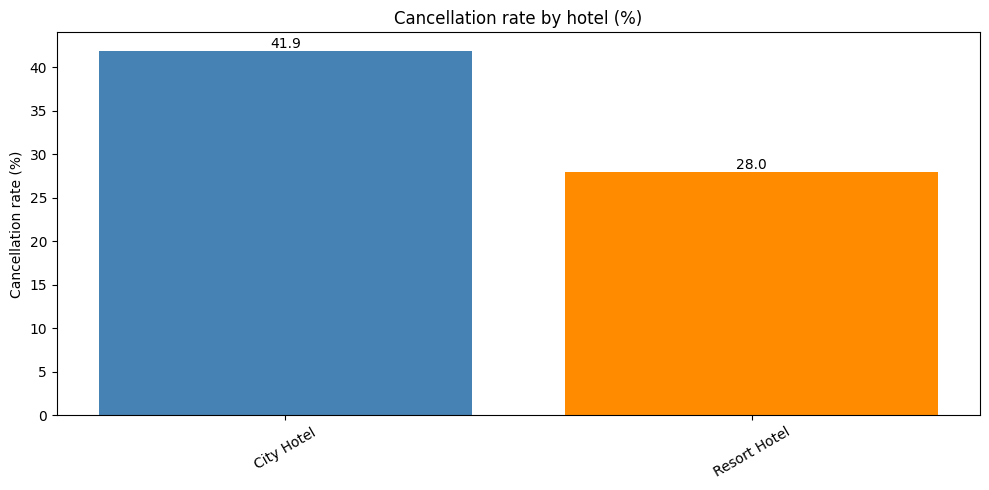

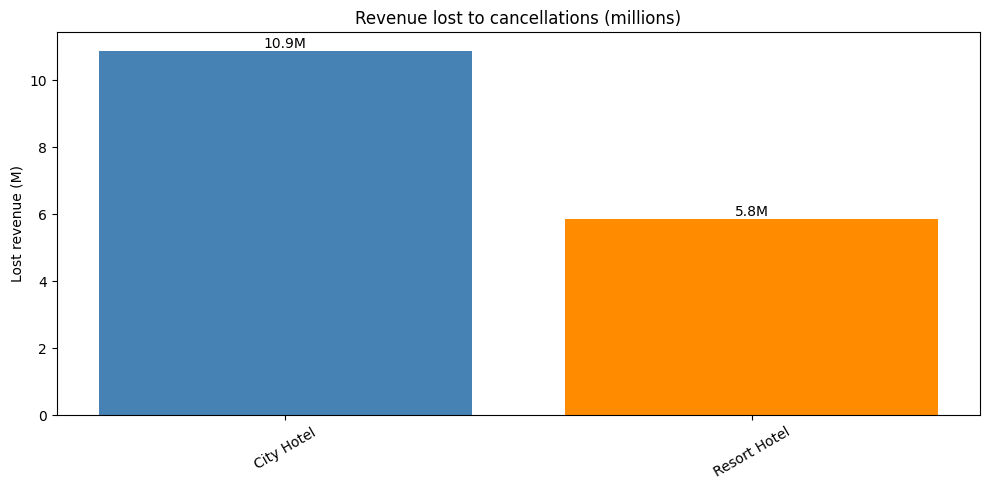

In [27]:
bar_with_labels(hotel_kpis.index, hotel_kpis["cancel_rate_%"], "Cancellation rate by hotel (%)", "Cancellation rate (%)",
                color=["steelblue", "darkorange"])
bar_with_labels(hotel_kpis.index, hotel_kpis["lost_revenue"] / 1000000, "Revenue lost to cancellations (millions)",
                "Lost revenue (M)", color=["steelblue", "darkorange"], fmt="{:.1f}M")

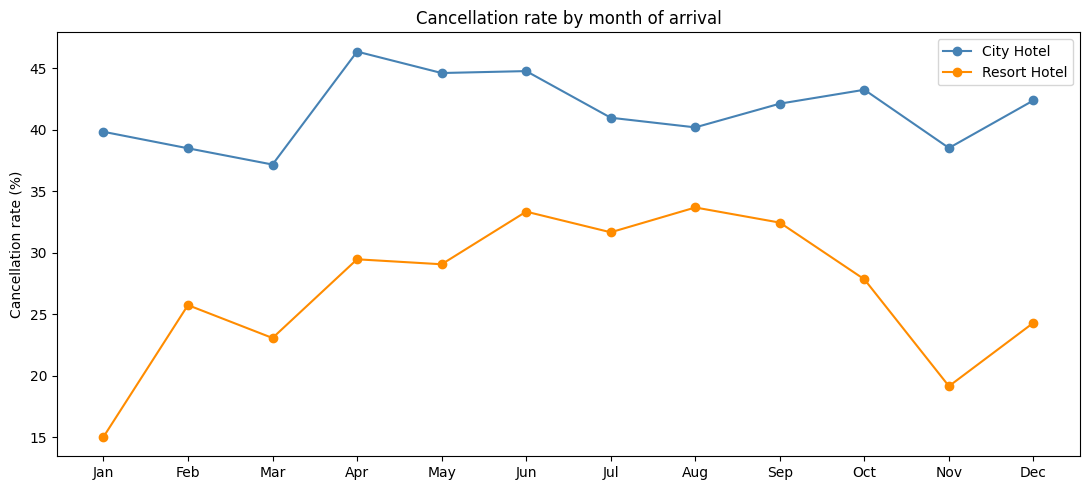

    arrival_month_num         hotel  cancel_rate_%
0                   1    City Hotel           39.8
1                   1  Resort Hotel           15.0
2                   2    City Hotel           38.5
3                   2  Resort Hotel           25.7
4                   3    City Hotel           37.2
5                   3  Resort Hotel           23.1
6                   4    City Hotel           46.4
7                   4  Resort Hotel           29.5
8                   5    City Hotel           44.6
9                   5  Resort Hotel           29.1
10                  6    City Hotel           44.8
11                  6  Resort Hotel           33.3
12                  7    City Hotel           41.0
13                  7  Resort Hotel           31.7
14                  8    City Hotel           40.2
15                  8  Resort Hotel           33.7
16                  9    City Hotel           42.1
17                  9  Resort Hotel           32.5
18                 10    City H

In [28]:
# Cancellation rate by month of arrival, one line per hotel
month_hotel = clean.groupby(["arrival_month_num", "hotel"])["is_canceled"].mean().reset_index()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(11, 5))
for hotel_name, color in [("City Hotel", "steelblue"), ("Resort Hotel", "darkorange")]:
    part = month_hotel[month_hotel["hotel"] == hotel_name]
    plt.plot(part["arrival_month_num"], part["is_canceled"] * 100, marker="o", color=color, label=hotel_name)
plt.xticks(range(1, 13), month_labels)
plt.title("Cancellation rate by month of arrival")
plt.ylabel("Cancellation rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

month_hotel["cancel_rate_%"] = round(month_hotel["is_canceled"] * 100, 1)
print(month_hotel[["arrival_month_num", "hotel", "cancel_rate_%"]])

In [29]:
# By year (rates), and a like-for-like comparison of January - August
display(summary_by(["arrival_date_year", "hotel"]))

jan_aug = clean[clean["arrival_month_num"] <= 8]
for year in [2016, 2017]:
    print(year, "Jan-Aug:", kpis(jan_aug[jan_aug["arrival_date_year"] == year]))

,arrival_date_year,hotel,bookings,cancel_rate,avg_adr,realised_revenue,lost_revenue,lost_share_%
0,2015,City Hotel,13608,44.1,86.3,1894306.0,1397337.0,42.5
1,2015,Resort Hotel,8210,26.0,90.5,2617236.0,909173.0,25.8
2,2016,City Hotel,37892,40.6,104.0,6855612.0,4922053.0,41.8
3,2016,Resort Hotel,18342,26.8,88.8,4811093.0,2269647.0,32.1
4,2017,City Hotel,27396,42.6,118.0,5635425.0,4560222.0,44.7
5,2017,Resort Hotel,13113,30.9,109.2,4173305.0,2663358.0,39.0


2016 Jan-Aug: {'bookings': 36495, 'cancel_rate_%': 34.9, 'avg_adr': 100.5, 'realised_revenue': 7961036, 'lost_revenue': 4731042, 'lost_share_%': 37.3}
2017 Jan-Aug: {'bookings': 40509, 'cancel_rate_%': 38.8, 'avg_adr': 115.13, 'realised_revenue': 9808730, 'lost_revenue': 7223580, 'lost_share_%': 42.4}


In [30]:
# By season
season_table = summary_by(["season", "hotel"])
season_table

,season,hotel,bookings,cancel_rate,avg_adr,realised_revenue,lost_revenue,lost_share_%
0,Autumn,City Hotel,19240,41.8,101.7,3285322.0,2345546.0,41.7
1,Autumn,Resort Hotel,9013,27.1,69.7,1948856.0,759444.0,28.0
2,Spring,City Hotel,22052,43.0,110.0,4034118.0,3254816.0,44.7
3,Spring,Resort Hotel,10411,27.3,72.3,2111110.0,1050427.0,33.2
4,Summer,City Hotel,24878,41.9,115.2,5128975.0,3776564.0,42.4
5,Summer,Resort Hotel,12409,32.9,158.0,6468598.0,3654360.0,36.1
6,Winter,City Hotel,12726,40.1,86.3,1936926.0,1502686.0,43.7
7,Winter,Resort Hotel,7832,22.3,59.0,1073070.0,377946.0,26.0



--- Lead time ---
  lead_time_band  bookings  cancel_rate
0       0-7 days     19244          9.7
1      8-30 days     18848         28.0
2     31-90 days     29436         37.8
3    91-180 days     26384         44.8
4   181-365 days     21505         55.5
5      365+ days      3144         67.7


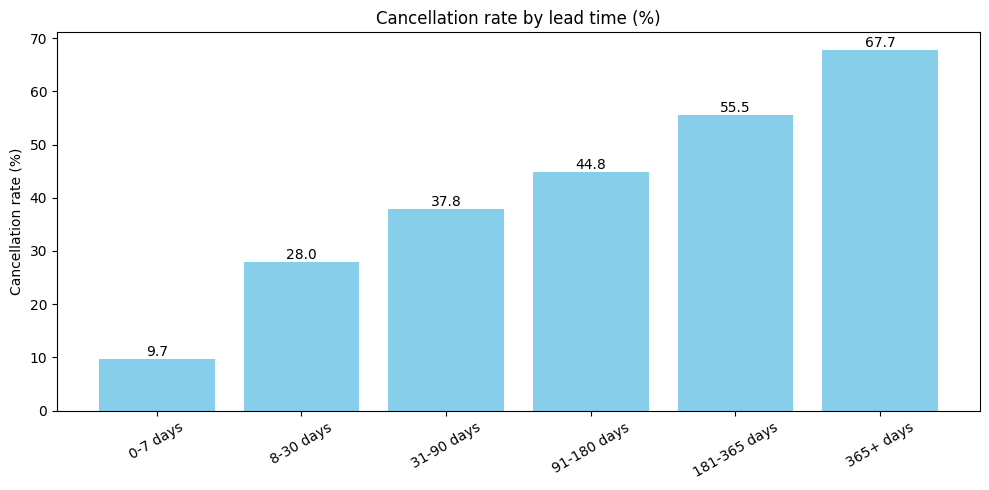


--- Deposit type ---
  deposit_type  bookings  cancel_rate
0   No Deposit    103813         28.6
1   Non Refund     14586         99.4
2   Refundable       162         22.2


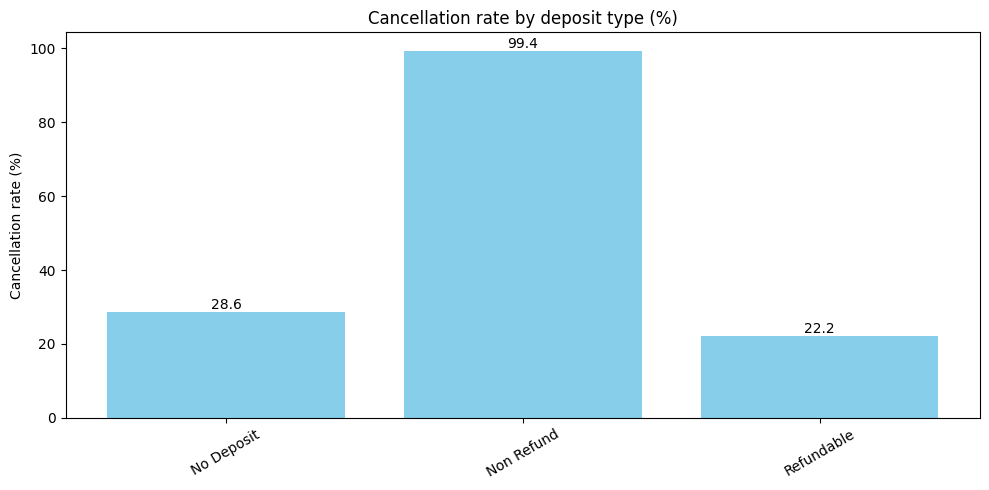


--- Previous cancellations ---
  prev_cancel_band  bookings  cancel_rate
0                0    112086         34.1
1                1      6044         94.5
2               2+       431         52.9


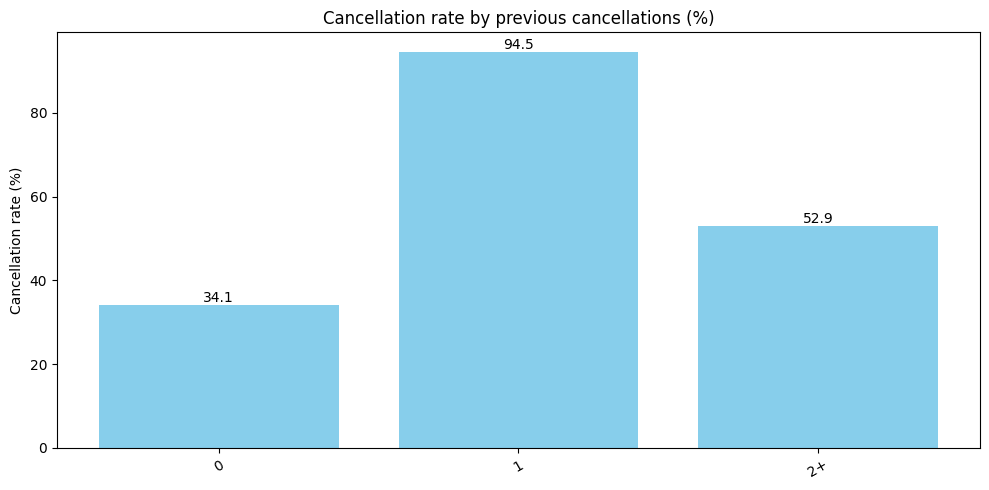


--- Booking changes ---
  changes_band  bookings  cancel_rate
0            0    100712         41.1
1            1     12573         14.3
2            2      3757         20.3
3           3+      1519         17.1


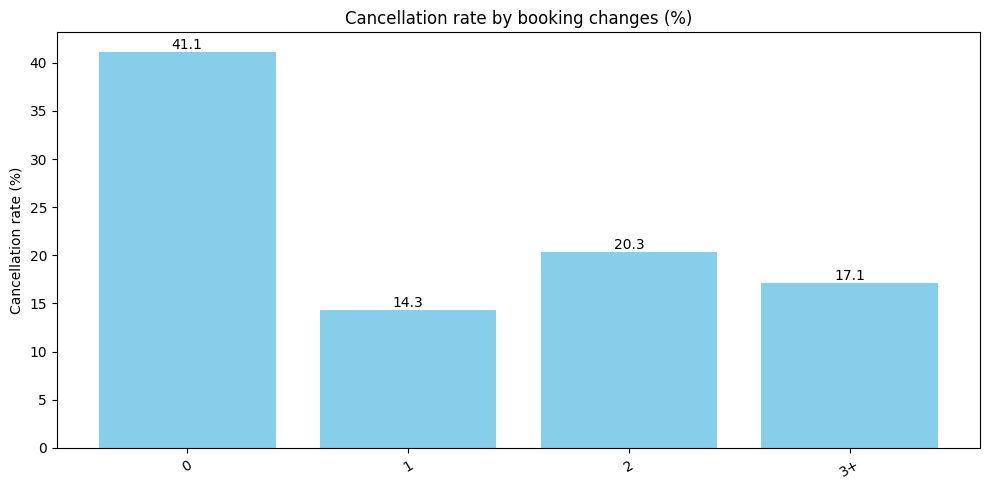


--- Special requests ---
  requests_band  bookings  cancel_rate
0             0     69798         48.0
1             1     33004         22.1
2             2     12893         22.2
3            3+      2866         16.9


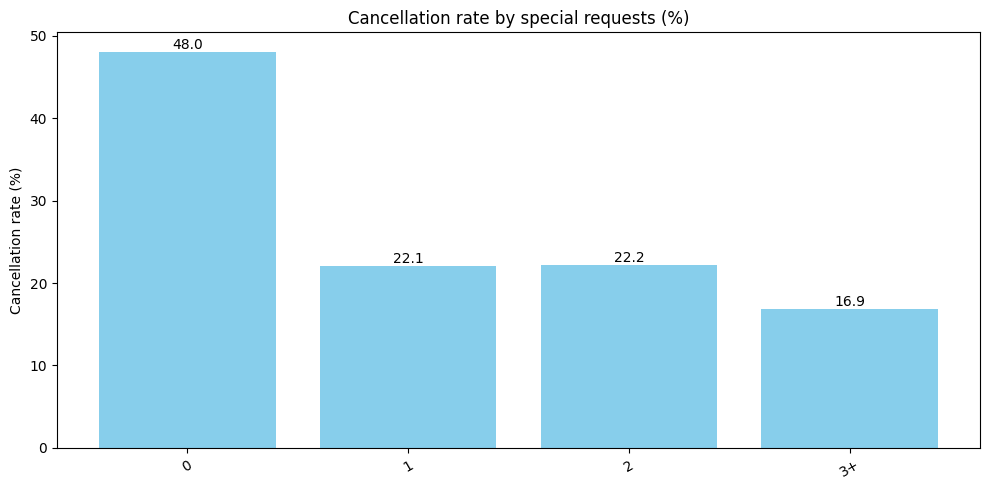


--- Waiting list ---
  waiting_band  bookings  cancel_rate
0       0 days    114869         36.4
1    1-30 days       591         75.6
2     31+ days      3101         61.7


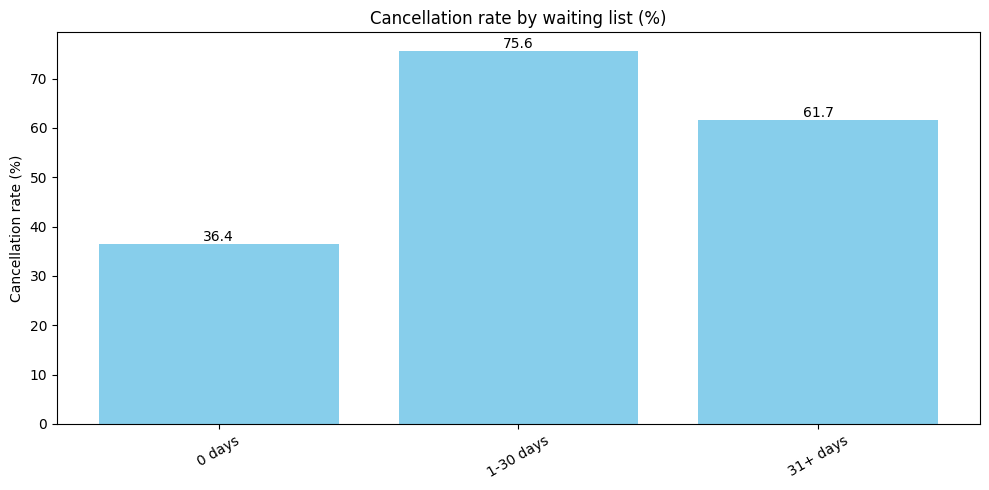


--- Parking ---
        parking_band  bookings  cancel_rate
0         No parking    111168         39.7
1  Parking requested      7393          0.0


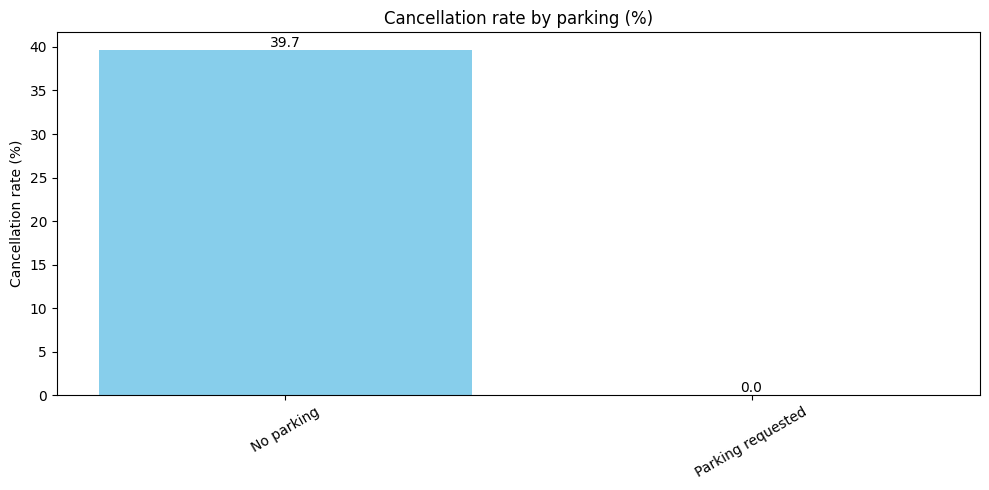

In [31]:
# Objective 2: Booking factors linked to cancellations

# Grouping count columns into bands so that they are easy to compare
clean["prev_cancel_band"] = pd.cut(clean["previous_cancellations"], bins=[-1, 0, 1, 100], labels=["0", "1", "2+"])
clean["changes_band"] = pd.cut(clean["booking_changes"], bins=[-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
clean["requests_band"] = pd.cut(clean["total_of_special_requests"], bins=[-1, 0, 1, 2, 10], labels=["0", "1", "2", "3+"])
clean["waiting_band"] = pd.cut(clean["days_in_waiting_list"], bins=[-1, 0, 30, 1000], labels=["0 days", "1-30 days", "31+ days"])
clean["parking_band"] = pd.cut(clean["required_car_parking_spaces"], bins=[-1, 0, 10], labels=["No parking", "Parking requested"])

factors = {
    "Lead time": "lead_time_band",
    "Deposit type": "deposit_type",
    "Previous cancellations": "prev_cancel_band",
    "Booking changes": "changes_band",
    "Special requests": "requests_band",
    "Waiting list": "waiting_band",
    "Parking": "parking_band",
}

# A loop over the factors: one table and one chart for each
for label, column in factors.items():
    table = summary_by(column)
    print(f"\n--- {label} ---")
    print(table[[column, "bookings", "cancel_rate"]])
    bar_with_labels(table[column].astype(str), table["cancel_rate"], f"Cancellation rate by {label.lower()} (%)",
                    "Cancellation rate (%)")

is_canceled                    1.000
lead_time                      0.292
previous_cancellations         0.110
days_in_waiting_list           0.054
adr                            0.040
total_nights                   0.014
is_repeated_guest             -0.078
booking_changes               -0.145
required_car_parking_spaces   -0.197
total_of_special_requests     -0.236
Name: is_canceled, dtype: float64


Text(0.5, 1.0, 'Correlation Matrix Heatmap: booking factors and cancellation')

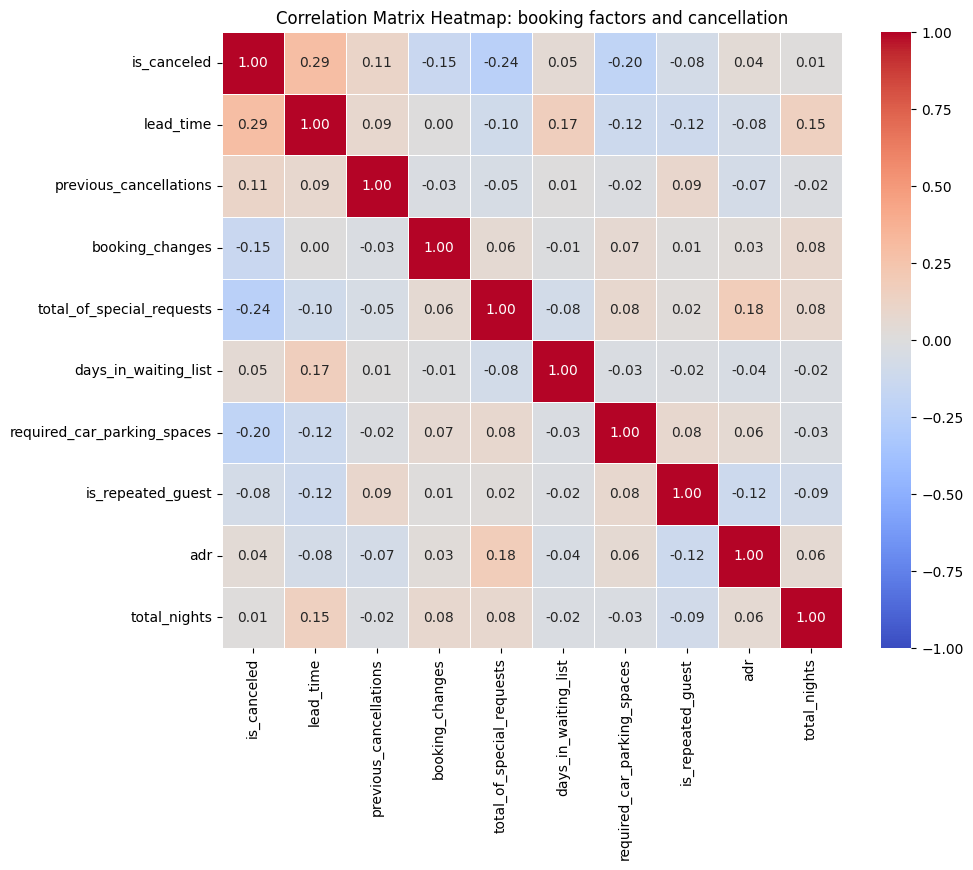

In [32]:
# Correlation of the numeric booking factors with is_canceled
factor_cols = ["is_canceled", "lead_time", "previous_cancellations", "booking_changes", "total_of_special_requests",
               "days_in_waiting_list", "required_car_parking_spaces", "is_repeated_guest", "adr", "total_nights"]
corr_matrix = clean[factor_cols].corr()

print(round(corr_matrix["is_canceled"].sort_values(ascending=False), 3))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Matrix Heatmap: booking factors and cancellation")

In [34]:
# Investigation: why are Non-Refund bookings cancelled 99% of the time?
non_refund = clean[clean["deposit_type"] == "Non Refund"]
no_deposit = clean[clean["deposit_type"] == "No Deposit"]


def deposit_profile(data):
    return {
        "bookings": len(data),
        "cancel_rate_%": round(data["is_canceled"].mean() * 100, 1),
        "from_Portugal_%": round((data["country"] == "PRT").mean() * 100, 1),
        "Groups_or_Offline_TA_%": round(((data["market_segment"] == "Groups").mean() +
                                         (data["market_segment"] == "Offline TA/TO").mean()) * 100, 1),
        "median_lead_time": data["lead_time"].median(),
        "has_special_requests_%": round((data["total_of_special_requests"] > 0).mean() * 100, 1),
        "duplicate_rows_%": round(data.drop(columns=["Booking_ID"]).duplicated().mean() * 100, 1),
    }


pd.DataFrame([deposit_profile(non_refund), deposit_profile(no_deposit)], index=["Non Refund", "No Deposit"]).T

,Non Refund,No Deposit
bookings,14586.0,103813.0
cancel_rate_%,99.4,28.6
from_Portugal_%,97.2,32.5
Groups_or_Offline_TA_%,97.2,28.4
median_lead_time,183.0,57.0
has_special_requests_%,0.2,46.9
duplicate_rows_%,92.9,18.6


,risk_level,bookings,share_of_bookings_%,cancel_rate,lost_revenue
1,Low,22659,19.1,7.3,411866.0
2,Medium,62944,53.1,29.5,8648926.0
0,High,32958,27.8,72.6,7660997.0


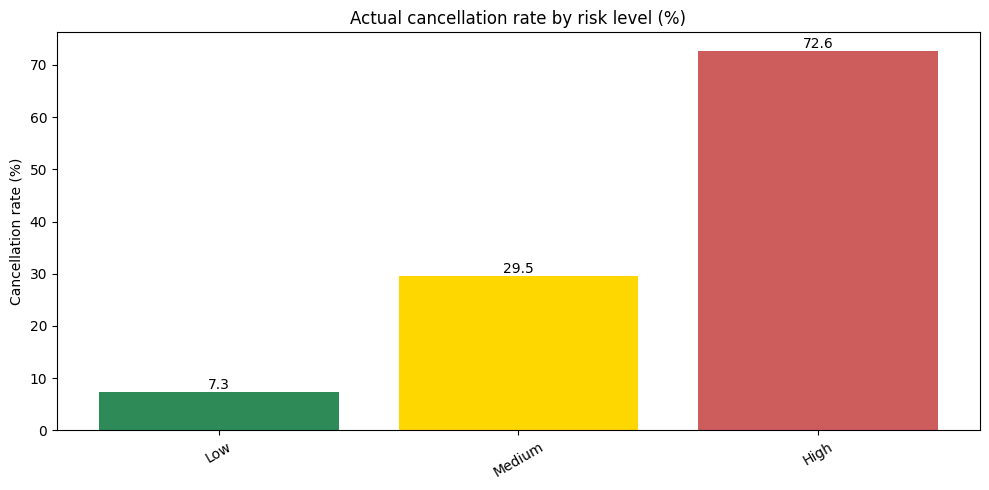

In [35]:
def risk_level(row):
    if row["deposit_type"] == "Non Refund" or row["previous_cancellations"] > 0:
        return "High"
    elif row["lead_time"] > 90 and row["total_of_special_requests"] == 0 and row["booking_changes"] == 0:
        return "High"
    elif row["lead_time"] > 30 and row["total_of_special_requests"] == 0:
        return "Medium"
    elif row["required_car_parking_spaces"] > 0 or row["is_repeated_guest"] == 1 or row["lead_time"] <= 7:
        return "Low"
    else:
        return "Medium"


clean["risk_level"] = clean.apply(risk_level, axis=1)
risk_table = summary_by("risk_level")
risk_table["share_of_bookings_%"] = round(risk_table["bookings"] / len(clean) * 100, 1)
risk_table = risk_table.sort_values("cancel_rate")
display(risk_table[["risk_level", "bookings", "share_of_bookings_%", "cancel_rate", "lost_revenue"]])

bar_with_labels(risk_table["risk_level"], risk_table["cancel_rate"], "Actual cancellation rate by risk level (%)",
                "Cancellation rate (%)", color=["seagreen", "gold", "indianred"])

In [36]:
# Objective 3: Market segments and distribution channels

segment_table = summary_by("market_segment").sort_values("realised_revenue", ascending=False)
segment_table["revenue_share_%"] = round(segment_table["realised_revenue"] / segment_table["realised_revenue"].sum() * 100, 1)
segment_table

,market_segment,bookings,cancel_rate,avg_adr,realised_revenue,lost_revenue,lost_share_%,revenue_share_%
6,Online TA,56129,36.9,117.9,13707139.0,10227646.0,42.7,52.7
5,Offline TA/TO,24048,34.5,87.7,5659292.0,2486958.0,30.5,21.8
3,Direct,12449,15.5,116.9,4097842.0,993410.0,19.5,15.8
4,Groups,19758,61.2,79.7,1869130.0,2800544.0,60.0,7.2
2,Corporate,5231,18.9,70.2,577892.0,196383.0,25.4,2.2
0,Aviation,231,22.1,102.7,70868.0,16578.0,19.0,0.3
1,Complementary,715,12.2,3.0,4813.0,270.0,5.3,0.0


In [37]:
channel_table = summary_by("distribution_channel").sort_values("bookings", ascending=False)
channel_table["share_of_bookings_%"] = round(channel_table["bookings"] / len(clean) * 100, 1)
channel_table

,distribution_channel,bookings,cancel_rate,avg_adr,realised_revenue,lost_revenue,lost_share_%,share_of_bookings_%
3,TA/TO,97334,41.2,103.8,20802010.0,15281172.0,42.3,82.1
1,Direct,14450,17.6,108.1,4323529.0,1140859.0,20.9,12.2
0,Corporate,6584,22.2,70.3,827865.0,286209.0,25.7,5.6
2,GDS,190,19.5,122.5,33008.0,12989.0,28.2,0.2
4,Undefined,3,66.7,67.1,564.0,560.0,49.8,0.0


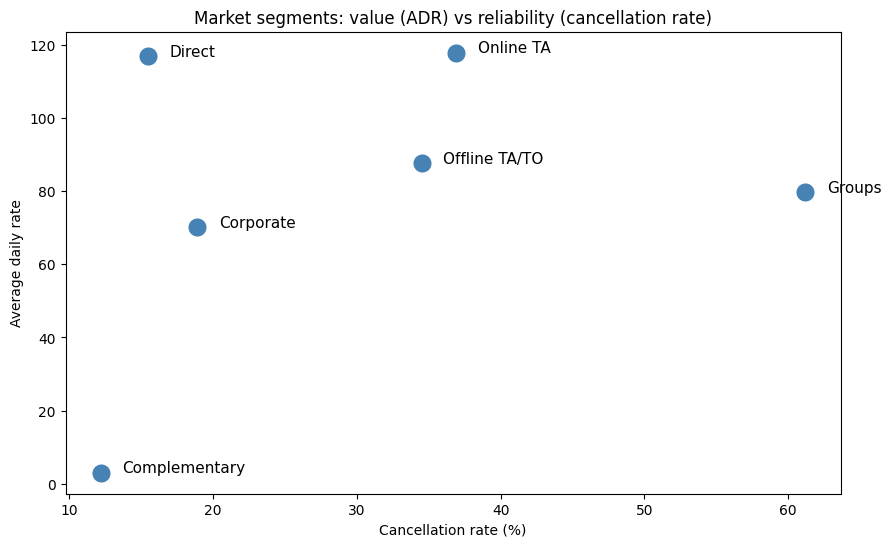

In [38]:
# Value vs reliability: ADR against cancellation rate for each segment
main_segments = segment_table[segment_table["bookings"] >= 500]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=main_segments, x="cancel_rate", y="avg_adr", color="steelblue", s=200)
for i in range(len(main_segments)):
    row = main_segments.iloc[i]
    plt.text(row["cancel_rate"] + 1.5, row["avg_adr"], row["market_segment"], fontsize=11)
plt.title("Market segments: value (ADR) vs reliability (cancellation rate)")
plt.xlabel("Cancellation rate (%)")
plt.ylabel("Average daily rate")
plt.show()

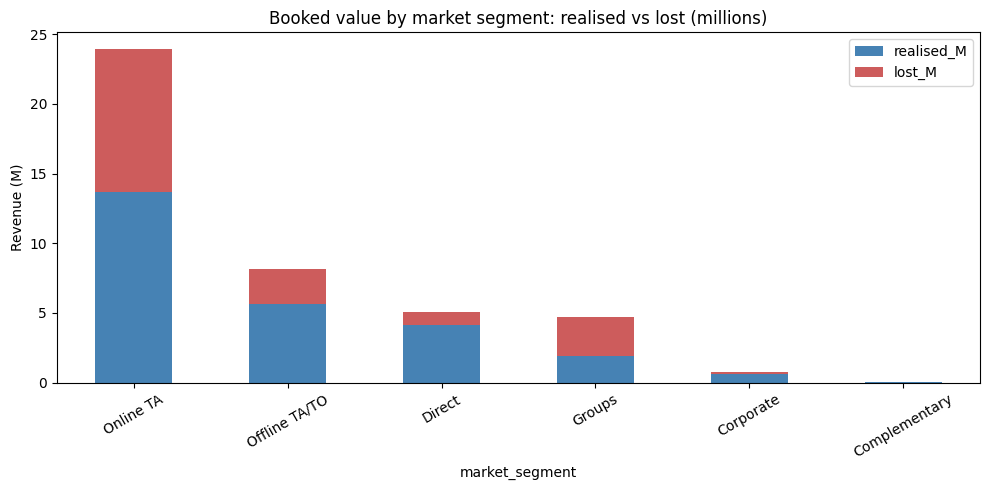

In [39]:
# Realised vs lost revenue by segment (stacked bar chart with pandas)
main_segments["realised_M"] = main_segments["realised_revenue"] / 1000000
main_segments["lost_M"] = main_segments["lost_revenue"] / 1000000
main_segments.plot(kind="bar", x="market_segment", y=["realised_M", "lost_M"], stacked=True,
                   color=["steelblue", "indianred"], figsize=(10, 5))
plt.title("Booked value by market segment: realised vs lost (millions)")
plt.ylabel("Revenue (M)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


--- Customer type ---
     customer_type  bookings  cancel_rate  avg_adr  realised_revenue
2        Transient     88934         41.0    107.8        19324676.0
3  Transient-Party     25002         25.5     86.5         5054099.0
0         Contract      4056         31.1     88.0         1484917.0
1            Group       569         10.2     84.7          123285.0


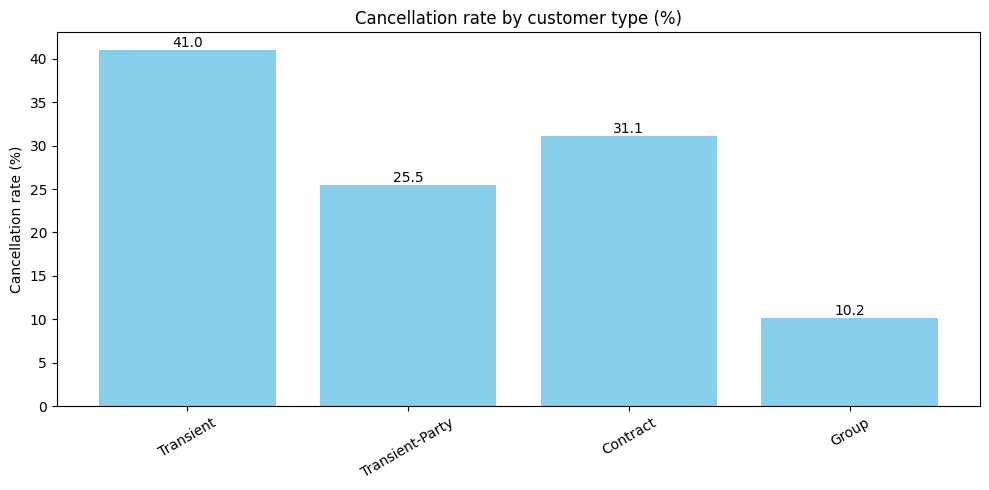


--- Repeat vs first-time ---
       guest_status  bookings  cancel_rate  avg_adr  realised_revenue
0  First-time guest    115063         37.9    103.5        25502367.0
1      Repeat guest      3498         15.7     70.2          484609.0


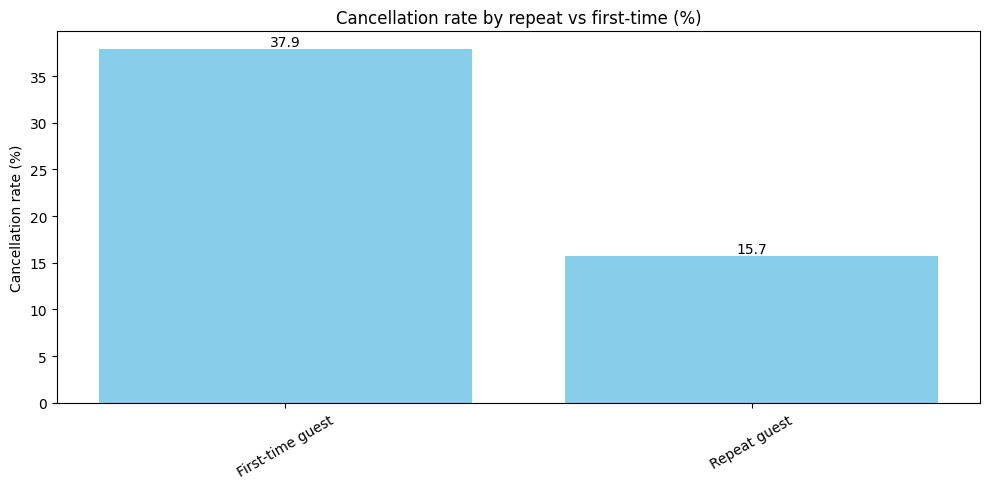


--- Meal plan ---
        meal  bookings  cancel_rate  avg_adr  realised_revenue
0         BB     91717         37.6    100.0        18669541.0
2         HB     14384         34.6    121.0         5034460.0
3         SC     10503         37.5     99.5         1669809.0
4  Undefined      1160         24.7     92.7          381491.0
1         FB       797         60.0    109.2          231675.0


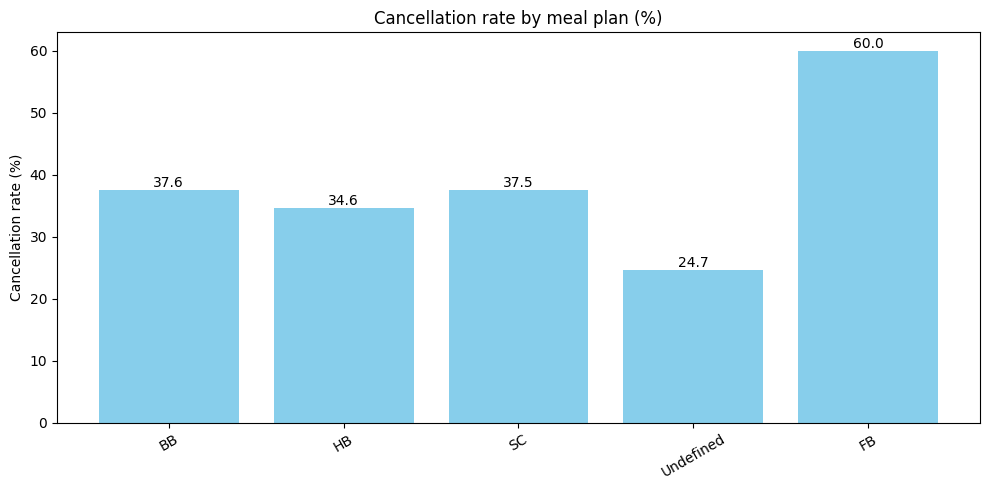


--- Party make-up ---
           party_type  bookings  cancel_rate  avg_adr  realised_revenue
0   Couple / 2 adults     81164         39.9     98.4        17462498.0
3          Solo adult     22377         29.2     82.3         3075165.0
1  Family (with kids)      9293         35.1    155.1         3351289.0
2  Group of 3+ adults      5727         34.2    153.4         2098024.0


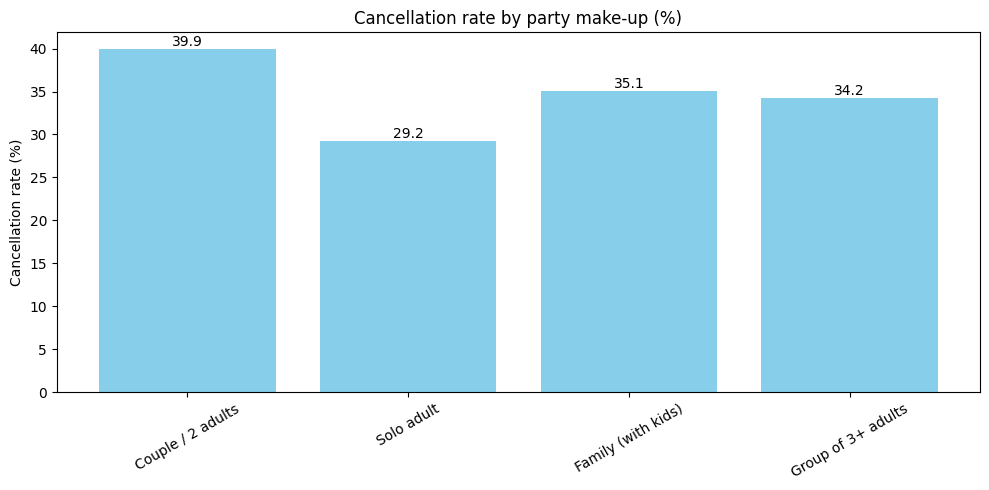

In [40]:
# Objective 4: Customer types and guest behaviour

guest_dimensions = {
    "Customer type": "customer_type",
    "Repeat vs first-time": "guest_status",
    "Meal plan": "meal",
    "Party make-up": "party_type",
}

for label, column in guest_dimensions.items():
    table = summary_by(column).sort_values("bookings", ascending=False)
    print(f"\n--- {label} ---")
    print(table[[column, "bookings", "cancel_rate", "avg_adr", "realised_revenue"]])
    bar_with_labels(table[column], table["cancel_rate"], f"Cancellation rate by {label.lower()} (%)", "Cancellation rate (%)")

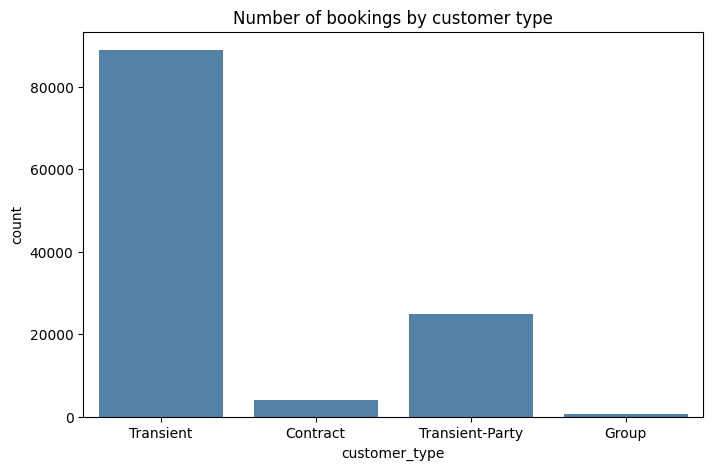

In [41]:
# Number of bookings by customer type
plt.figure(figsize=(8, 5))
sns.countplot(x="customer_type", data=clean, color="steelblue")
plt.title("Number of bookings by customer type")
plt.show()

In [42]:
# Repeat vs first-time guests: how they book
repeat_table = clean.groupby("guest_status").agg({"Booking_ID": "count", "is_canceled": "mean", "adr": "mean",
                                                  "total_nights": "mean", "lead_time": "median"})
repeat_table

,Booking_ID,is_canceled,adr,total_nights,lead_time
guest_status,,,,,
First-time guest,115063,0.379131,103.463087,3.48609,73.0
Repeat guest,3498,0.156947,70.194005,2.08948,4.0


,country,bookings,cancel_rate,avg_adr
135,PRT,47940,57.3,93.2
59,GBR,12094,20.3,96.3
56,FRA,10389,18.6,109.9
51,ESP,8544,25.5,117.3
43,DEU,7285,16.7,104.4
81,ITA,3756,35.5,114.3
76,IRL,3373,24.7,98.3
15,BEL,2338,20.2,114.0
25,BRA,2217,37.4,111.3
123,NLD,2101,18.4,108.2


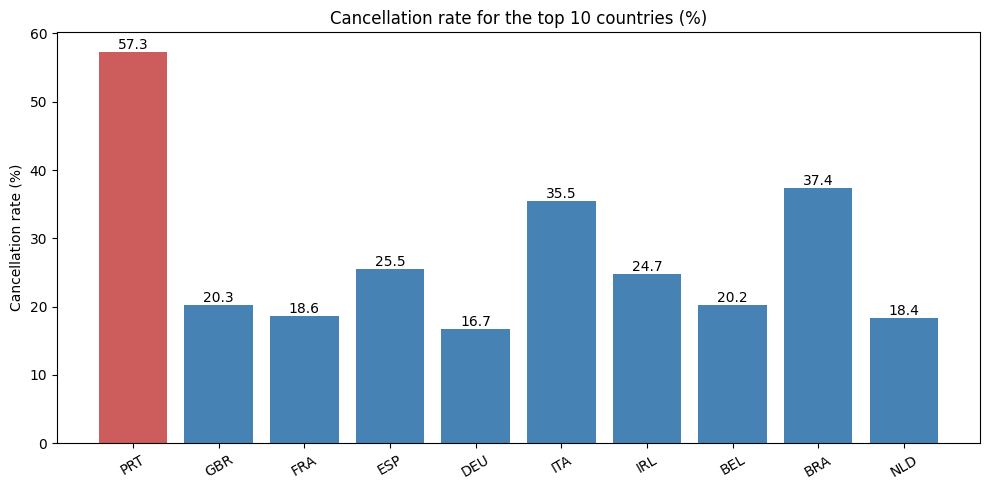

In [43]:
# Top 10 countries by number of bookings
country_table = summary_by("country").sort_values("bookings", ascending=False).head(10)
display(country_table[["country", "bookings", "cancel_rate", "avg_adr"]])

colors = []
for c in country_table["country"]:
    if c == "PRT":
        colors.append("indianred")
    else:
        colors.append("steelblue")
bar_with_labels(country_table["country"], country_table["cancel_rate"],
                "Cancellation rate for the top 10 countries (%)", "Cancellation rate (%)", color=colors)

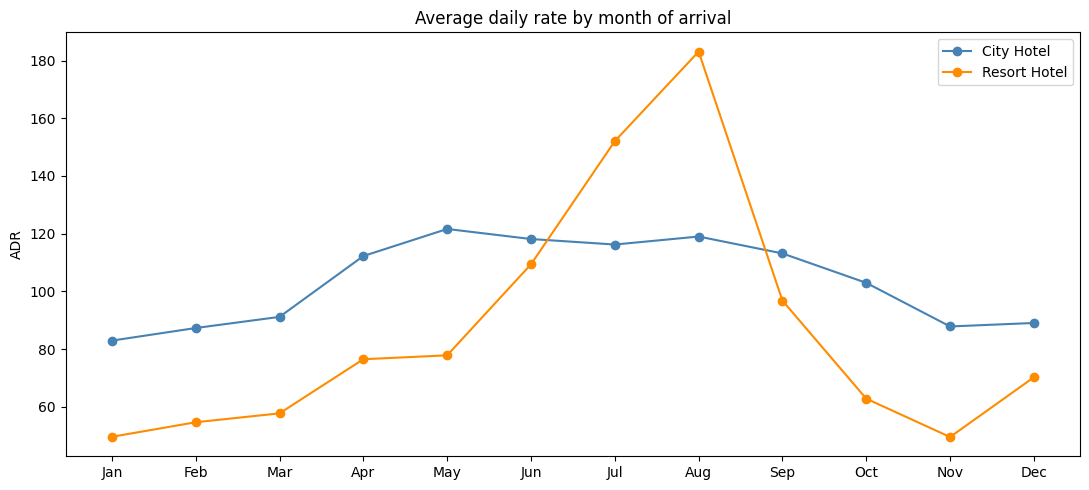

    arrival_month_num         hotel    adr
0                   1    City Hotel   82.9
1                   1  Resort Hotel   49.6
2                   2    City Hotel   87.3
3                   2  Resort Hotel   54.6
4                   3    City Hotel   91.2
5                   3  Resort Hotel   57.7
6                   4    City Hotel  112.2
7                   4  Resort Hotel   76.5
8                   5    City Hotel  121.6
9                   5  Resort Hotel   77.8
10                  6    City Hotel  118.1
11                  6  Resort Hotel  109.4
12                  7    City Hotel  116.2
13                  7  Resort Hotel  152.1
14                  8    City Hotel  119.0
15                  8  Resort Hotel  183.1
16                  9    City Hotel  113.1
17                  9  Resort Hotel   96.8
18                 10    City Hotel  103.0
19                 10  Resort Hotel   62.8
20                 11    City Hotel   87.8
21                 11  Resort Hotel   49.5
22         

In [44]:
# Objective 5: Pricing and demand patterns

# ADR of stays that actually happened, by month and hotel
stayed = clean[clean["is_canceled"] == 0]
adr_month = stayed.groupby(["arrival_month_num", "hotel"])["adr"].mean().reset_index()

plt.figure(figsize=(11, 5))
for hotel_name, color in [("City Hotel", "steelblue"), ("Resort Hotel", "darkorange")]:
    part = adr_month[adr_month["hotel"] == hotel_name]
    plt.plot(part["arrival_month_num"], part["adr"], marker="o", color=color, label=hotel_name)
plt.xticks(range(1, 13), month_labels)
plt.title("Average daily rate by month of arrival")
plt.ylabel("ADR")
plt.legend()
plt.tight_layout()
plt.show()

adr_month["adr"] = round(adr_month["adr"], 1)
print(adr_month)

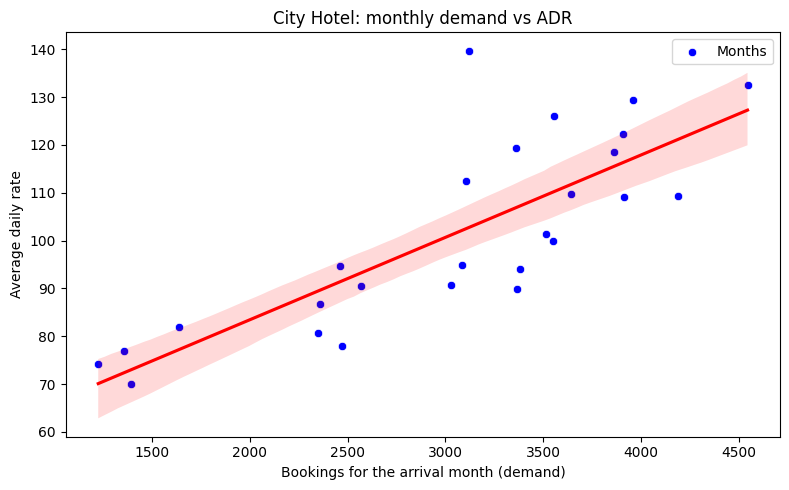

Correlation coefficient between demand and ADR (City Hotel): 0.80


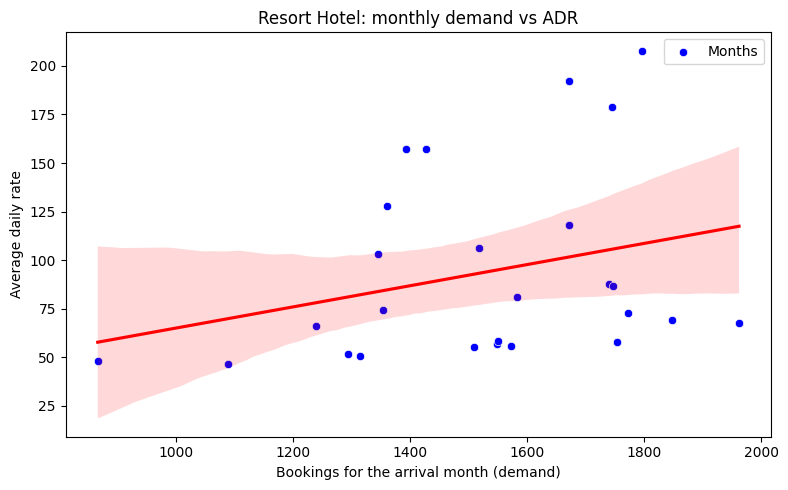

Correlation coefficient between demand and ADR (Resort Hotel): 0.29


In [45]:
# Demand (number of bookings per arrival month) vs ADR, for each hotel
demand = clean.groupby(["arrival_date_year", "arrival_month_num", "hotel"]).agg({"Booking_ID": "count", "adr": "mean"}).reset_index()
demand = demand.rename(columns={"Booking_ID": "bookings"})

for hotel_name in ["City Hotel", "Resort Hotel"]:
    part = demand[demand["hotel"] == hotel_name]
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=part, x="bookings", y="adr", color="blue", label="Months")
    sns.regplot(data=part, x="bookings", y="adr", scatter=False, color="red", line_kws={"label": "Trend Line"})
    plt.title(f"{hotel_name}: monthly demand vs ADR")
    plt.xlabel("Bookings for the arrival month (demand)")
    plt.ylabel("Average daily rate")
    plt.legend()
    plt.tight_layout()
    plt.show()
    correlation = part[["bookings", "adr"]].corr().iloc[0, 1]
    print(f"Correlation coefficient between demand and ADR ({hotel_name}): {correlation:.2f}")

In [46]:
# ADR and cancellation by length of stay
stay_table = summary_by(["stay_band", "hotel"])
stay_table[["stay_band", "hotel", "bookings", "avg_adr", "cancel_rate"]]

,stay_band,hotel,bookings,avg_adr,cancel_rate
0,1 night,City Hotel,13256,105.5,30.9
1,1 night,Resort Hotel,7747,75.6,15.1
2,2-3 nights,City Hotel,42785,103.9,46.5
3,2-3 nights,Resort Hotel,11910,92.5,30.2
4,4-7 nights,City Hotel,21634,109.3,38.7
5,4-7 nights,Resort Hotel,16004,106.1,32.1
6,8-14 nights,City Hotel,1069,114.3,52.2
7,8-14 nights,Resort Hotel,3727,106.9,28.9
8,15+ nights,City Hotel,152,99.6,77.0
9,15+ nights,Resort Hotel,277,69.3,45.1


,adr_band,hotel,bookings,cancel_rate
0,< 60,City Hotel,3272,33.8
1,< 60,Resort Hotel,13902,23.0
2,60-90,City Hotel,27769,45.2
3,60-90,Resort Hotel,10303,29.2
4,90-120,City Hotel,25288,40.8
5,90-120,Resort Hotel,4821,26.5
6,120-160,City Hotel,15964,40.8
7,120-160,Resort Hotel,4412,30.5
8,160+,City Hotel,6603,39.0
9,160+,Resort Hotel,6227,36.7


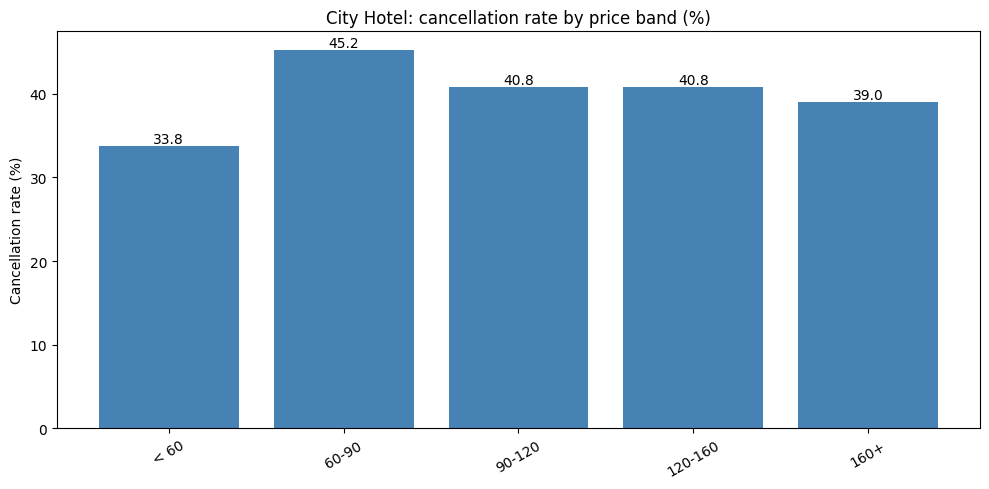

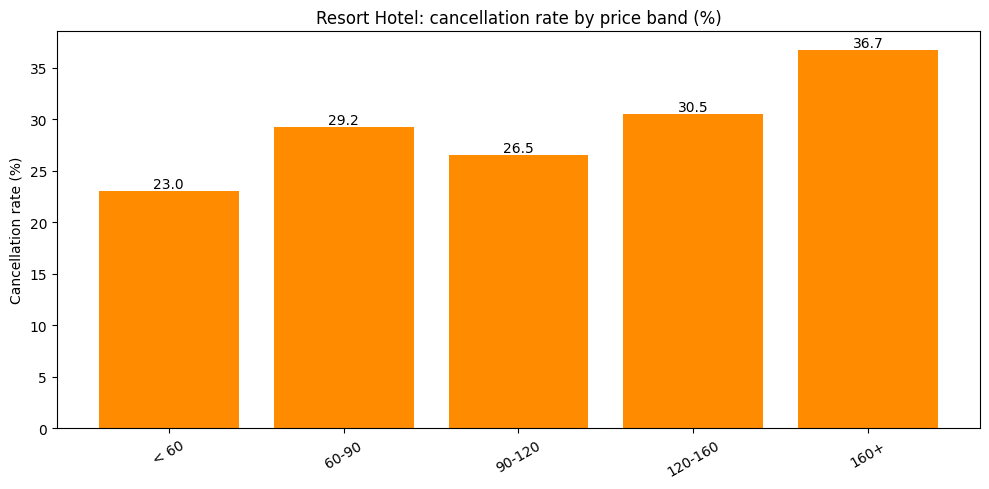

City Hotel: correlation between ADR and cancellation = -0.025
Resort Hotel: correlation between ADR and cancellation = 0.102


In [47]:
# Does price affect cancellation? ADR bands within each hotel
clean["adr_band"] = pd.cut(clean["adr"], bins=[-1, 60, 90, 120, 160, 1000],
                           labels=["< 60", "60-90", "90-120", "120-160", "160+"])
price_table = summary_by(["adr_band", "hotel"])
display(price_table[["adr_band", "hotel", "bookings", "cancel_rate"]])

for hotel_name, color in [("City Hotel", "steelblue"), ("Resort Hotel", "darkorange")]:
    part = price_table[price_table["hotel"] == hotel_name]
    bar_with_labels(part["adr_band"].astype(str), part["cancel_rate"], f"{hotel_name}: cancellation rate by price band (%)",
                    "Cancellation rate (%)", color=color)

for hotel_name in ["City Hotel", "Resort Hotel"]:
    part = clean[clean["hotel"] == hotel_name]
    r = part[["adr", "is_canceled"]].corr().iloc[0, 1]
    print(f"{hotel_name}: correlation between ADR and cancellation = {r:.3f}")

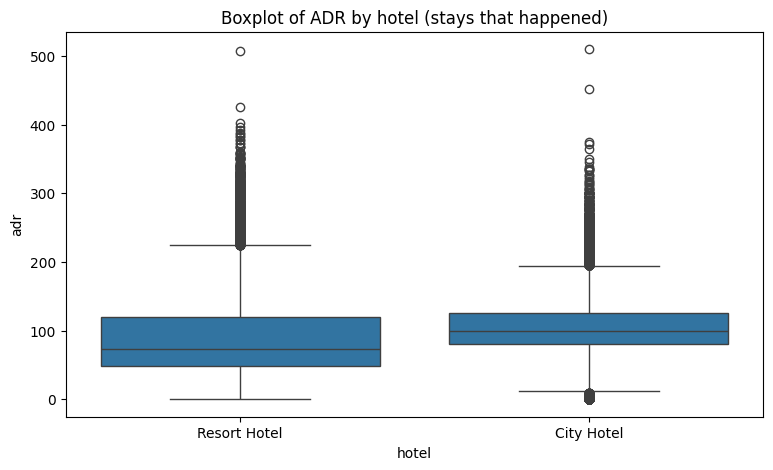

In [48]:
# Distribution of ADR for each hotel
plt.figure(figsize=(9, 5))
sns.boxplot(x="hotel", y="adr", data=stayed)
plt.title("Boxplot of ADR by hotel (stays that happened)")
plt.show()